# MOSFET Characterization (Generic)

This notebook runs SPICE simulations on any N-channel MOSFET model using NgSpice via direct subprocess (batch mode) with proper convergence settings and realistic parasitic drain resistance (1 mOhm).

**Topology**: VDD+ -> R_drain -> Drain, VDD- (ground) -> Source, VGS+ -> Gate, VGS- -> Source (ground).

MOSFET source is node 0 (ground).

**Configuration**: Edit the MODEL_CONFIG section below to change MOSFET.

**Model limitation**: BSIM3 (Level 7) models used here are calibrated for low-Vds switching (Rds_on, gate charge, capacitances). Currents at Vds > 2V are over-predicted — BSIM3 lacks the drift-region physics present in real vertical DMOS. See `ROOT_CAUSE_IDMAX.md` for analysis and fix options.


In [ ]:
import sys
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import subprocess
import os
import re
from pathlib import Path

matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['font.size'] = 12

# ============================================================
# MODEL CONFIGURATION - Change these to switch MOSFETs
# ============================================================
MODEL_NAME = 'csd18510kcs'           # Model name (subcircuit name in .lib)
LIB_FILENAME = 'ng_csd18510kcs.lib'  # Converted ngspice library file
R_DRAIN = 0.0                        # Series drain resistance (ohm)
VGS_RANGE = (0, 10, 11)              # (start, stop, num_points) for output curves
VDS_RANGE = (0, 40, 0.1)             # (start, stop, step) for output curves
VGS_TRANSFER = (0, 10, 0.1)          # (start, stop, step) for transfer curve
VDD_TRANSFER = 10                    # Vdd for transfer curve (V)

# --- Measurement conditions ---
ID_CONTMAX = 95.0                    # Max continuous drain current (A)
CAP_VDS = 20.0                       # Vds for capacitance measurement (V)
CAP_VGS = 0.0                        # Vgs for capacitance measurement (V)
CAP_FREQ = 1e6                       # Frequency for capacitance measurement (Hz)
QG_VDS = 10.0                        # Vds for gate charge measurement (V)

# --- Datasheet validation ranges (set to None to skip validation) ---
DATASHEET_CISS_RANGE = (8770, 11400)   # (low, high) pF; or None
DATASHEET_COSS_RANGE = (832, 1080)     # (low, high) pF; or None
DATASHEET_CRSS_RANGE = (424, 551)       # (low, high) pF; or None
DATASHEET_QG_10V_RANGE = (118, 153)    # (low, high) nC; or None
DATASHEET_QG_4V5_RANGE = (58, 75)      # (low, high) nC; or None
DATASHEET_RG_RANGE = (0.9, 1.8)        # (low, high) ohm; or None
DATASHEET_RDS_RANGE = None             # (low, high) mOhm; or None
DATASHEET_VTH_RANGE = None             # (low, high) V; or None
# ============================================================

# Dynamic paths - find project root by looking for SpiceModels dir
def find_project_root():
    '''Find project root by searching for SpiceModels directory.'''
    cwd = Path.cwd()
    for path in [cwd] + list(cwd.parents):
        if (path / 'SpiceModels').exists():
            return path
    return cwd  # fallback

PROJECT_ROOT = find_project_root()
SPICE_MODELS_DIR = PROJECT_ROOT / 'SpiceModels'
LIB_PATH = SPICE_MODELS_DIR / LIB_FILENAME
WORK_DIR = PROJECT_ROOT
NGSPICE_CMD = r'C:\\Progra~1\\Spice64\\bin\\ngspice_con.exe'

# Auto-convert PSpice model if ngspice version doesn't exist
if not LIB_PATH.exists():
    pspice_lib = SPICE_MODELS_DIR / LIB_FILENAME.replace('ng_', '')
    if pspice_lib.exists():
        print(f"Converting {pspice_lib.name} -> {LIB_FILENAME}...")
        import subprocess
        result = subprocess.run([
            sys.executable, str(PROJECT_ROOT / 'convert_spice.py'), str(pspice_lib)
        ], capture_output=True, text=True, cwd=WORK_DIR)
        if result.returncode == 0:
            print("Conversion successful!")
        else:
            print(f"Conversion failed: {result.stderr}")
            raise FileNotFoundError(f"Could not create {LIB_FILENAME}")
    else:
        raise FileNotFoundError(f"Neither {LIB_FILENAME} nor {pspice_lib.name} found in {SPICE_MODELS_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Library: {LIB_PATH}")
print(f"Library exists: {LIB_PATH.exists()}")

# Extract model parameters from .lib file
def extract_model_params(lib_path):
    '''Extract key parameters from ngspice .lib file.'''
    content = lib_path.read_text(encoding='utf-8', errors='replace')
    
    params = {}
    
    # Extract .PARAM values (handles both 'name = value' and 'name value')
    param_pattern = re.compile(r'\.PARAM\s+(\w+)\s*=?\s*([^\n]+)')
    for match in param_pattern.finditer(content):
        name = match.group(1).lower()
        value_str = match.group(2).strip().rstrip(';')
        # Try to evaluate simple expressions
        try:
            # Clean up braces and fix common typos
            value_str = value_str.strip('{}').replace('}e-6', 'e-6')
            # Replace common parameter references with their values
            value_str = value_str.replace('pAA', str(params.get('paa', '10.856327')))
            value_str = value_str.replace('pWIDTH', str(params.get('pwidth', '1')))
            params[name] = float(eval(value_str))
        except:
            params[name] = value_str
    
    # Ensure numeric params are floats (handle string expressions)
    for key in ['pwidth', 'paa', 'perim', 'prgate', 'pcjo', 'ptrc1', 'ptrc2']:
        if key in params and isinstance(params[key], str):
            try:
                val = params[key].replace('}e-6', 'e-6')
                val = val.replace('pAA', str(params.get('paa', '10.856327')))
                params[key] = float(eval(val))
            except:
                pass
    
    # Extract explicit capacitor values from subcircuit - CGD0, CGS0, CDS0
    cgd0_match = re.search(r'CGD0\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    cgs0_match = re.search(r'CGS0\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    cds0_match = re.search(r'CDS0\s+\d+\s+\d+\s+\{([^}]+)\}', content)
    if cgd0_match:
        params['cgd0'] = float(cgd0_match.group(1))
    if cgs0_match:
        params['cgs0'] = float(cgs0_match.group(1))
    if cds0_match:
        try:
            cds0_expr = cds0_match.group(1).replace('pwidth', str(params.get('pwidth', 1)))
            params['cds0'] = float(eval(cds0_expr))
        except:
            params['cds0'] = 5.63e-12 * float(params.get('pwidth', 1))
    
# Extract diode model parameters (DBD, DD) - use simpler patterns
    dbd_cjo_match = re.search(r'\.MODEL\s+DBD\s+D\s*\([^)]*CJO\s*=\s*([\d.eE+-]+)', content)
    dd_cjo_match = re.search(r'\.MODEL\s+DD\s+D\s*\([^)]*CJO\s*=\{([^}]+)\}', content)
    dbd_vj_match = re.search(r'\.MODEL\s+DBD\s+D\s*\([^)]*VJ\s*=\s*([\d.eE+-]+)', content)
    dd_vj_match = re.search(r'\.MODEL\s+DD\s+D\s*\([^)]*VJ\s*=\s*([\d.eE+-]+)', content)
    # M after VJ: VJ=0.99 M=1.038
    dbd_m_match = re.search(r'\.MODEL\s+DBD\s+D\s*\([^)]*VJ\s*=[\d.eE+-]+\s+M\s*=\s*([\d.eE+-]+)', content)
    dd_m_match = re.search(r'\.MODEL\s+DD\s+D\s*\([^)]*VJ\s*=[\d.eE+-]+\s+M\s*=\s*([\d.eE+-]+)', content)
    dbd_fc_match = re.search(r'\.MODEL\s+DBD\s+D\s*\([^)]*FC\s*=\s*([\d.eE+-]+)', content)
    dd_fc_match = re.search(r'\.MODEL\s+DD\s+D\s*\([^)]*FC\s*=\s*([\d.eE+-]+)', content)
    
    if dbd_cjo_match:
        params['dbd_cjo'] = float(dbd_cjo_match.group(1))
    if dd_cjo_match:
        cjo_expr = dd_cjo_match.group(1).replace('pCJO', str(params.get('pcjo', '58e-12')))
        params['dd_cjo'] = float(eval(cjo_expr))
    if dbd_vj_match:
        params['dbd_vj'] = float(dbd_vj_match.group(1))
    if dd_vj_match:
        params['dd_vj'] = float(dd_vj_match.group(1))
    if dbd_m_match:
        params['dbd_m'] = float(dbd_m_match.group(1))
    if dd_m_match:
        params['dd_m'] = float(dd_m_match.group(1))
    if dbd_fc_match:
        params['dbd_fc'] = float(dbd_fc_match.group(1))
    if dd_fc_match:
        params['dd_fc'] = float(dd_fc_match.group(1))
    
    # Extract NMOS overlap capacitances
    cgso_match = re.search(r'\.MODEL\s+NMOS\s+NMOS\s*\([^)]*CGSO\s*=\s*([\d.eE+-]+)', content)
    cgdo_match = re.search(r'\.MODEL\s+NMOS\s+NMOS\s*\([^)]*CGDO\s*=\s*([\d.eE+-]+)', content)
    if cgso_match:
        params['cgso'] = float(cgso_match.group(1))
    if cgdo_match:
        params['cgdo'] = float(cgdo_match.group(1))
    
    # Extract gate resistance
    rg_match = re.search(r'RGG\s+\d+\s+\d+\s+\{([^}]+)\}', content)
    if rg_match:
        try:
            rg_expr = rg_match.group(1).replace('pRgate', str(params.get('prgate', '0.9')))
            params['rggate'] = float(eval(rg_expr))
        except:
            params['rggate'] = 1.5
    
    # Extract L from M1 instance (format: M1 ... W={pwidth} L=0.70u ...)
    l_match = re.search(r'M1\s+\d+\s+\d+\s+\d+\s+\d+\s+\w+\s+W=\{pwidth\}\s+L=([\d.]+)[uUmM]', content)
    if l_match:
        params['l_extracted'] = float(l_match.group(1)) * 1e-6  # in meters
    else:
        # Try alternative pattern
        l_match2 = re.search(r'L=([\d.]+)[uUmM]', content)
        if l_match2:
            params['l_extracted'] = float(l_match2.group(1)) * 1e-6
    
    return params

model_params = extract_model_params(LIB_PATH)
print(f"Model: {MODEL_NAME}")
print(f"Working dir: {WORK_DIR}")
print(f"Series drain resistance: {R_DRAIN} ohm")
print(f"Extracted params: {list(model_params.keys())}")
for k, v in model_params.items():
    print(f"  {k} = {v}")

# Common capacitance parameters (with defaults from model)
CGSO = model_params.get('cgso', 17e-12)
CGDO = model_params.get('cgdo', 13.2e-12)
CGD0 = model_params.get('cgd0', 0.5e-12)
CGS0 = model_params.get('cgs0', 4e-12)
CDS0 = model_params.get('cds0', 5.63e-12 * model_params.get('pwidth', 1))

# Diode junction capacitances
DBD_CJO = model_params.get('dbd_cjo', 274e-12)
DD_CJO = model_params.get('dd_cjo', 2 * model_params.get('pcjo', 58e-12))
DBD_VJ = model_params.get('dbd_vj', 0.99)
DD_VJ = model_params.get('dd_vj', 0.65)
DBD_M = model_params.get('dbd_m', 1.038)
DD_M = model_params.get('dd_m', 1.55)
DBD_FC = model_params.get('dbd_fc', 0.5)
DD_FC = model_params.get('dd_fc', 0.90)

# Gate resistance
RGGATE = model_params.get('rggate', 1.5)

# Datasheet validation ranges (from config - user adjustable)
DATASHEET_CISS_RANGE = DATASHEET_CISS_RANGE
DATASHEET_COSS_RANGE = DATASHEET_COSS_RANGE
DATASHEET_CRSS_RANGE = DATASHEET_CRSS_RANGE
DATASHEET_QG_10V_RANGE = DATASHEET_QG_10V_RANGE
DATASHEET_QG_4V5_RANGE = DATASHEET_QG_4V5_RANGE
DATASHEET_RG_RANGE = DATASHEET_RG_RANGE
DATASHEET_RDS_RANGE = DATASHEET_RDS_RANGE
DATASHEET_VTH_RANGE = DATASHEET_VTH_RANGE

# Geometry from model params - evaluate expressions if needed
paa = model_params.get('paa', 10.856327)
pwidth = model_params.get('pwidth', paa / 0.8 * 2)

# Handle case where pwidth is an expression string
if isinstance(pwidth, str):
    try:
        pwidth = float(eval(pwidth.strip('{}').replace('pAA', str(paa))))
    except:
        pwidth = paa / 0.8 * 2

W = pwidth * 1e6  # um
L = model_params.get('l_extracted', 0.70e-6) * 1e6  # um
print(f"Geometry: W = {W:.2f} um, L = {L:.2f} um, W/L = {W/L:.1f}")

Project root: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice
Library: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice\SpiceModels\ng_csd18510kcs.lib
Library exists: True
Model: csd18510kcs
Working dir: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice
Series drain resistance: 0.0 ohm
Extracted params: ['ptrc1', 'ptrc2', 'paa', 'pwidth', 'perim', 'prgate', 'pcjo', 'cgd0', 'cgs0', 'cds0', 'dbd_cjo', 'dd_cjo', 'dbd_vj', 'dd_vj', 'dbd_m', 'dd_m', 'dbd_fc', 'dd_fc', 'cgso', 'cgdo', 'rggate', 'l_extracted']
  ptrc1 = 0.0055
  ptrc2 = 1.31e-05
  paa = 10.856327
  pwidth = 2.71408175e-05
  perim = 2.1*pwidth
  prgate = 0.9
  pcjo = 5.8e-11
  cgd0 = 5e-13
  cgs0 = 4e-12
  cds0 = 1.5280280252500001e-16
  dbd_cjo = 2.74e-10
  dd_cjo = 1.16e-10
  dbd_vj = 0.99
  dd_vj = 0.65
  dbd_m = 1.038
  dd_m = 1.55
  dbd_fc = 0.5
  dd_fc = 0.9
  cgso = 1.7e-11
  cgdo = 1.32e-11
  rggate = 1.5
  l_extracted = 7e-07
Geometry: W = 27.14 um, L = 0.70 um, W/L = 38.8


In [ ]:
def run_ngspice(netlist: str, timeout=120):
    '''Run ngspice batch mode and return stdout lines.'''
    import tempfile
    with tempfile.NamedTemporaryFile(mode='w', suffix='.cir', dir=WORK_DIR, delete=False) as f:
        f.write(netlist)
        netlist_path = f.name
    
    try:
        result = subprocess.run(
            [NGSPICE_CMD, '-b', netlist_path],
            capture_output=True,
            text=True,
            cwd=WORK_DIR,
            timeout=timeout
        )
        lines = result.stdout.split('\n')
        return lines, result.returncode, result.stderr
    finally:
        try:
            os.remove(netlist_path)
        except:
            pass

def parse_dc_output(lines):
    '''Parse DC sweep output from ngspice stdout.'''
    data_started = False
    x_vals = []
    y_vals = []
    for line in lines:
        if 'v-sweep' in line and ('vdd#branch' in line or 'vgs#branch' in line):
            data_started = True
            continue
        if data_started and line.strip():
            parts = line.split()
            if len(parts) >= 3:
                try:
                    idx = float(parts[0])
                    x = float(parts[1])
                    y = float(parts[2])
                    x_vals.append(x)
                    y_vals.append(y)
                except:
                    pass
    return np.array(x_vals), np.array(y_vals)

def run_dc_sweep_vds(vgs_val, vdd_start=VDS_RANGE[0], vdd_stop=VDS_RANGE[1], vdd_step=VDS_RANGE[2]):
    '''Run DC sweep of Vdd at fixed Vgs.'''
    # Build drain connection - direct if R_DRAIN=0, with resistor otherwise
    if R_DRAIN > 0:
        drain_connection = f'''Vdd vdd_node 0 {vdd_stop}
Vgs gate 0 {vgs_val}
Rdrain vdd_node drain {R_DRAIN}'''
    else:
        drain_connection = f'''Vdd drain 0 {vdd_stop}
Vgs gate 0 {vgs_val}'''
    
    netlist = f'''.title {MODEL_NAME}_Output_Vgs{vgs_val}
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {LIB_PATH}

XM1 drain gate 0 {MODEL_NAME}
{drain_connection}

.dc Vdd {vdd_start} {vdd_stop} {vdd_step}
.print dc I(Vdd)
.end
'''
    lines, rc, stderr = run_ngspice(netlist)
    if rc != 0:
        print(f"  [Vgs={vgs_val}V] ngspice failed (rc={rc}): {stderr[:200]}")
        return np.array([]), np.array([])
    return parse_dc_output(lines)

def run_dc_sweep_vgs(vdd_fixed=VDD_TRANSFER, vgs_start=VGS_TRANSFER[0], vgs_stop=VGS_TRANSFER[1], vgs_step=VGS_TRANSFER[2]):
    '''Run DC sweep of Vgs at fixed Vdd.'''
    # Build drain connection - direct if R_DRAIN=0, with resistor otherwise
    if R_DRAIN > 0:
        drain_connection = f'''Vdd vdd_node 0 {vdd_fixed}
Vgs gate 0 0
Rdrain vdd_node drain {R_DRAIN}'''
    else:
        drain_connection = f'''Vdd drain 0 {vdd_fixed}
Vgs gate 0 0'''
    
    netlist = f'''.title {MODEL_NAME}_Transfer_Vdd{vdd_fixed}
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {LIB_PATH}

XM1 drain gate 0 {MODEL_NAME}
{drain_connection}

.dc Vgs {vgs_start} {vgs_stop} {vgs_step}
.print dc I(Vdd)
.end
'''
    lines, rc, stderr = run_ngspice(netlist)
    if rc != 0:
        print(f"  [Vdd={vdd_fixed}V] ngspice failed (rc={rc}): {stderr[:200]}")
        return np.array([]), np.array([])
    return parse_dc_output(lines)

In [ ]:
# Run DC sweep: Id vs Vds for multiple Vgs values
vgs_values = np.linspace(*VGS_RANGE)

id_vds_data = {}

for vgs in vgs_values:
    vds_swept, id_swept = run_dc_sweep_vds(vgs)
    id_vds_data[vgs] = (vds_swept, id_swept)
    
    if len(vds_swept) > 0:
        print(f"  Vgs={vgs:.1f}V: Id max={np.max(np.abs(id_swept))*1e3:.1f} mA, points={len(vds_swept)}")
    else:
        print(f"  Vgs={vgs:.1f}V: No data returned")

  Vgs=0.0V: Id max=0.0 mA, points=400
  Vgs=1.0V: Id max=5.5 mA, points=400
  Vgs=2.0V: Id max=124541.0 mA, points=400
  Vgs=3.0V: Id max=1797580.0 mA, points=400
  Vgs=4.0V: Id max=3637160.0 mA, points=400


  Vgs=5.0V: Id max=5067540.0 mA, points=400
  Vgs=6.0V: Id max=6159300.0 mA, points=400


  Vgs=7.0V: Id max=7044670.0 mA, points=400
  Vgs=8.0V: Id max=7802640.0 mA, points=400
  Vgs=9.0V: Id max=8484320.0 mA, points=400
  Vgs=10.0V: Id max=9110830.0 mA, points=400


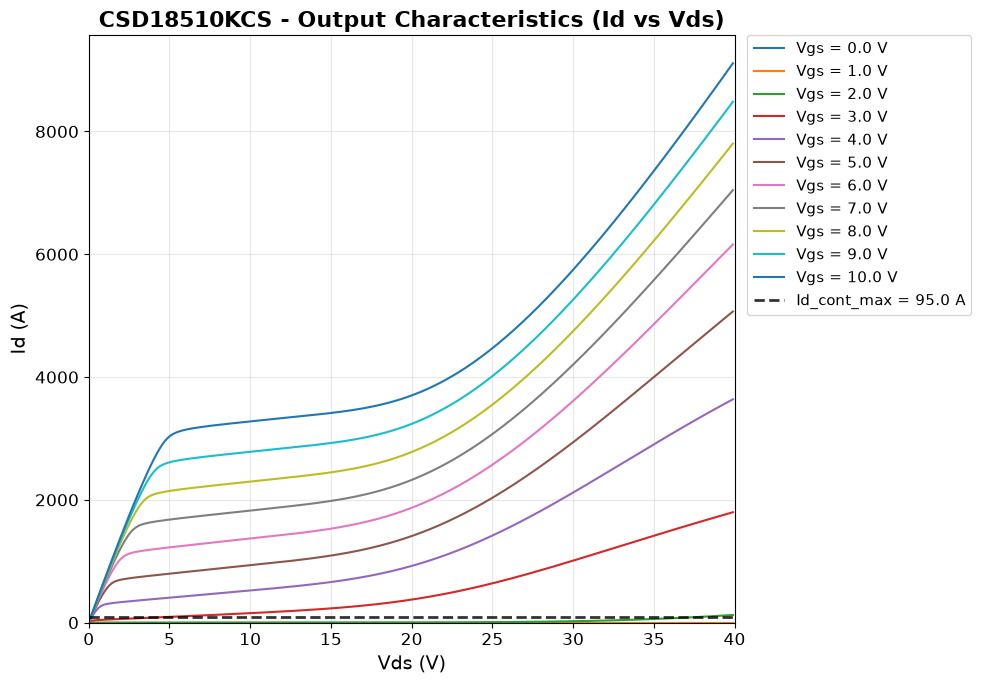

In [ ]:
# Plot Id-Vds curves (Output Characteristics)
fig, ax = plt.subplots(figsize=(10, 7))

for vgs, (vds, id_vals) in id_vds_data.items():
    if len(vds) > 0:
        ax.plot(vds, np.abs(id_vals), label=f'Vgs = {vgs:.1f} V', linewidth=1.5)
    else:
        ax.axhline(y=0, color=f'C{int(vgs)}', linestyle='--', alpha=0.5, linewidth=1)

# Add ID_CONTMAX horizontal line
ax.axhline(y=ID_CONTMAX, color='k', linestyle='--', linewidth=2, label=f'Id_cont_max = {ID_CONTMAX} A', alpha=0.8)

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Id (A)', fontsize=14)
ax.set_title(f'{MODEL_NAME.upper()} - Output Characteristics (Id vs Vds)', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax.set_xlim(VDS_RANGE[0], VDS_RANGE[1])
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

Transfer curve at Vdd=10V: 101 points, Id max=3277280.0 mA


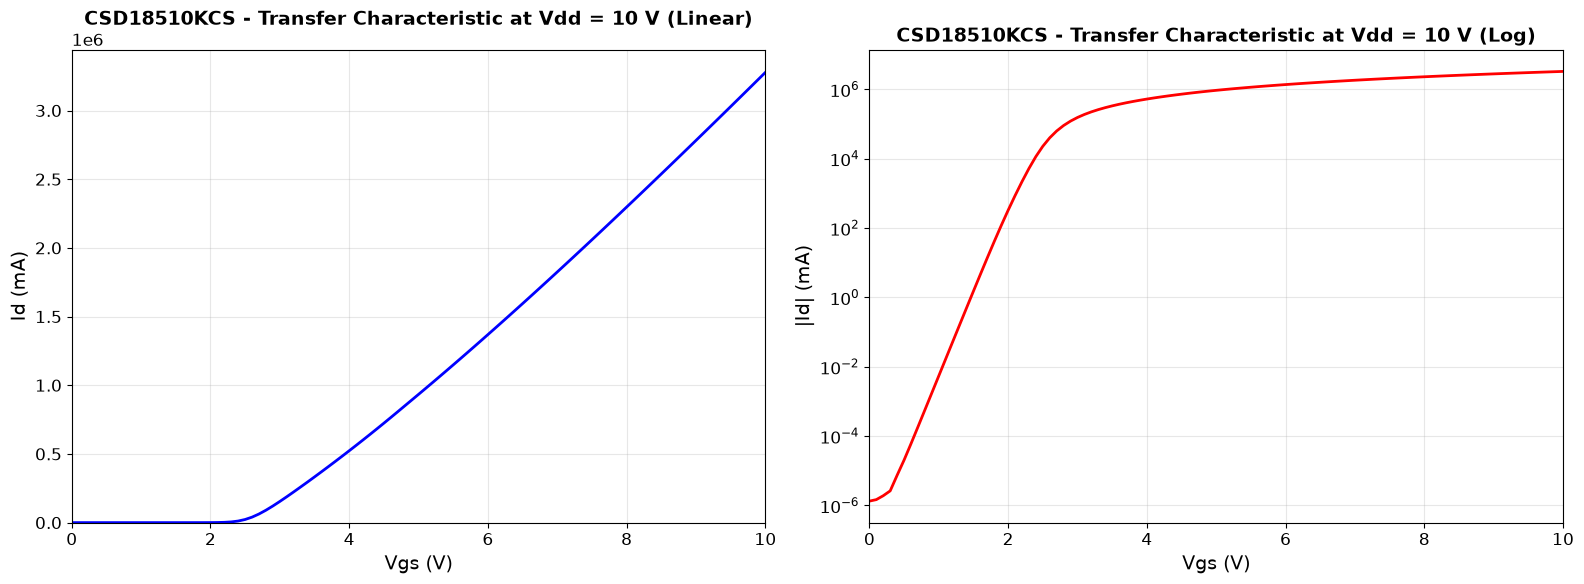

In [ ]:
# Run transfer characteristic: Id vs Vgs at fixed Vdd
vdd_fixed = VDD_TRANSFER

vgs_swept, id_vgs = run_dc_sweep_vgs(vdd_fixed)

print(f"Transfer curve at Vdd={vdd_fixed}V: {len(vgs_swept)} points, Id max={np.max(np.abs(id_vgs))*1e3:.1f} mA")

# Plot Transfer Characteristics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Linear scale
ax1.plot(vgs_swept, np.abs(id_vgs) * 1e3, 'b-', linewidth=2)
ax1.set_xlabel('Vgs (V)', fontsize=14)
ax1.set_ylabel('Id (mA)', fontsize=14)
ax1.set_title(f'{MODEL_NAME.upper()} - Transfer Characteristic at Vdd = {vdd_fixed} V (Linear)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_xlim(VGS_TRANSFER[0], VGS_TRANSFER[1])
ax1.set_ylim(bottom=0)

# Log scale
ax2.semilogy(vgs_swept, np.abs(id_vgs) * 1e3, 'r-', linewidth=2)
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('|Id| (mA)', fontsize=14)
ax2.set_title(f'{MODEL_NAME.upper()} - Transfer Characteristic at Vdd = {vdd_fixed} V (Log)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, which='both')
ax2.set_xlim(VGS_TRANSFER[0], VGS_TRANSFER[1])

plt.tight_layout()
plt.show()

Capacitance conditions: Vgs=0.0V, Vds=20.0V, f=1MHz
  Ciss @ Vds=20.0V: 4094 pF
  Coss @ Vds=20.0V: 4621 pF
  Crss @ Vds=20.0V: 4073 pF
  Ciss: FAIL (datasheet: 8770-11400 pF, got 4094 pF)
  Coss: FAIL (datasheet: 832-1080 pF, got 4621 pF)
  Crss: FAIL (datasheet: 424-551 pF, got 4073 pF)


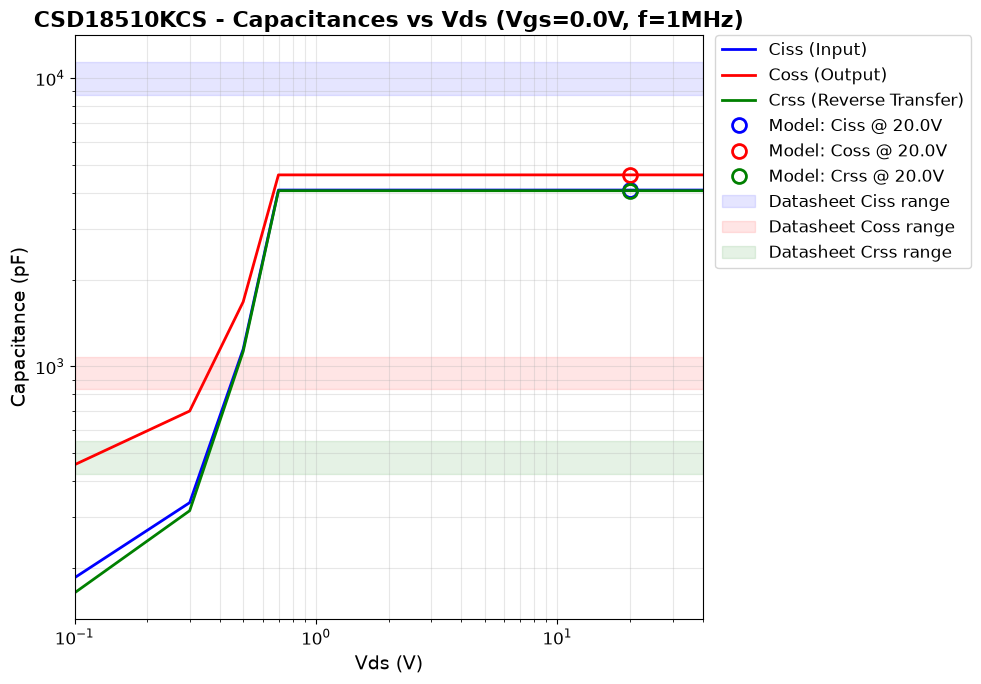

In [ ]:
# Capacitance extraction: Ciss, Coss, Crss vs Vds (using model parameters)
# Datasheet standard conditions: VGS=0V, VDS=20V, f=1MHz
# We compute at VGS=CAP_VGS, VDS=CAP_VDS, f=CAP_FREQ
# Model capacitances:
#  Ciss = CGS0 + CGSO + CGD0 + CGDO + C_DD(Vds)  (input at gate)
#  Coss = CDS0 + C_DBD(Vds) + C_DD(Vds)          (output at drain)
#  Crss = CGD0 + CGDO + C_DD(Vds)                 (reverse transfer)

print(f"Capacitance conditions: Vgs={CAP_VGS}V, Vds={CAP_VDS}V, f={CAP_FREQ/1e6:.0f}MHz")

vds_plot = np.linspace(0.1, 40, 201)

# Junction capacitance formula (clamped to avoid singularity at VJ*FC)
def c_junction(v, cjo, vj, m, fc):
    v_eff = min(v, vj * fc * 0.999)
    return cjo / (1 - v_eff/vj)**m

coss_plot = []
crss_plot = []
ciss_plot = []

for v in vds_plot:
    c_dbd = c_junction(v, DBD_CJO, DBD_VJ, DBD_M, DBD_FC)  # Body diode (drain-body)
    c_dd = c_junction(v, DD_CJO, DD_VJ, DD_M, DD_FC)       # DD diode (drain-gate)
    
    # Ciss = Cgs + Cgd = CGS0 + CGSO + CGD0 + CGDO + C_dd
    ciss = CGS0 + CGSO + CGD0 + CGDO + c_dd
    # Coss = Cds + Cdb = CDS0 + C_dbd + C_dd
    coss = CDS0 + c_dbd + c_dd
    # Crss = Cgd = CGD0 + CGDO + C_dd
    crss = CGD0 + CGDO + c_dd
    
    coss_plot.append(coss * 1e12)
    crss_plot.append(crss * 1e12)
    ciss_plot.append(ciss * 1e12)

# Mark the datasheet measurement point
idx_20v = np.argmin(np.abs(vds_plot - CAP_VDS))
ciss_20v = ciss_plot[idx_20v]
coss_20v = coss_plot[idx_20v]
crss_20v = crss_plot[idx_20v]

print(f"  Ciss @ Vds={CAP_VDS}V: {ciss_20v:.0f} pF")
print(f"  Coss @ Vds={CAP_VDS}V: {coss_20v:.0f} pF")
print(f"  Crss @ Vds={CAP_VDS}V: {crss_20v:.0f} pF")

# Datasheet validation
if DATASHEET_CISS_RANGE is not None:
    ciss_low, ciss_high = DATASHEET_CISS_RANGE
    if ciss_low <= ciss_20v <= ciss_high:
        print(f"  Ciss: PASS (datasheet: {ciss_low}-{ciss_high} pF)")
    else:
        print(f"  Ciss: FAIL (datasheet: {ciss_low}-{ciss_high} pF, got {ciss_20v:.0f} pF)")
if DATASHEET_COSS_RANGE is not None:
    coss_low, coss_high = DATASHEET_COSS_RANGE
    if coss_low <= coss_20v <= coss_high:
        print(f"  Coss: PASS (datasheet: {coss_low}-{coss_high} pF)")
    else:
        print(f"  Coss: FAIL (datasheet: {coss_low}-{coss_high} pF, got {coss_20v:.0f} pF)")
if DATASHEET_CRSS_RANGE is not None:
    crss_low, crss_high = DATASHEET_CRSS_RANGE
    if crss_low <= crss_20v <= crss_high:
        print(f"  Crss: PASS (datasheet: {crss_low}-{crss_high} pF)")
    else:
        print(f"  Crss: FAIL (datasheet: {crss_low}-{crss_high} pF, got {crss_20v:.0f} pF)")

# Plot Capacitances
fig, ax = plt.subplots(figsize=(10, 7))

ax.loglog(vds_plot, ciss_plot, 'b-', label='Ciss (Input)', linewidth=2)
ax.loglog(vds_plot, coss_plot, 'r-', label='Coss (Output)', linewidth=2)
ax.loglog(vds_plot, crss_plot, 'g-', label='Crss (Reverse Transfer)', linewidth=2)

# Mark datasheet point
ax.loglog([CAP_VDS], [ciss_20v], 'bo', markersize=10, markerfacecolor='none', markeredgewidth=2, label=f'Model: Ciss @ {CAP_VDS}V')
ax.loglog([CAP_VDS], [coss_20v], 'ro', markersize=10, markerfacecolor='none', markeredgewidth=2, label=f'Model: Coss @ {CAP_VDS}V')
ax.loglog([CAP_VDS], [crss_20v], 'go', markersize=10, markerfacecolor='none', markeredgewidth=2, label=f'Model: Crss @ {CAP_VDS}V')

# Mark datasheet range
if DATASHEET_CISS_RANGE is not None:
    ciss_low, ciss_high = DATASHEET_CISS_RANGE
    ax.axhspan(ciss_low, ciss_high, alpha=0.1, color='blue', label=f'Datasheet Ciss range')
if DATASHEET_COSS_RANGE is not None:
    coss_low, coss_high = DATASHEET_COSS_RANGE
    ax.axhspan(coss_low, coss_high, alpha=0.1, color='red', label=f'Datasheet Coss range')
if DATASHEET_CRSS_RANGE is not None:
    crss_low, crss_high = DATASHEET_CRSS_RANGE
    ax.axhspan(crss_low, crss_high, alpha=0.1, color='green', label=f'Datasheet Crss range')

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Capacitance (pF)', fontsize=14)
ax.set_title(f'{MODEL_NAME.upper()} - Capacitances vs Vds (Vgs={CAP_VGS}V, f={CAP_FREQ/1e6:.0f}MHz)', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3, which='both')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=12)
ax.set_xlim(0.1, 40)

plt.tight_layout()
plt.show()

Gate charge conditions: Vds=10.0V (constant)
  Qg(10V): FAIL (datasheet: 118-153 nC, got 0.0 nC)
  Qg(4.5V): FAIL (datasheet: 58-75 nC, got 0.0 nC)
  Rg: PASS (datasheet: 0.9-1.8 ohm)


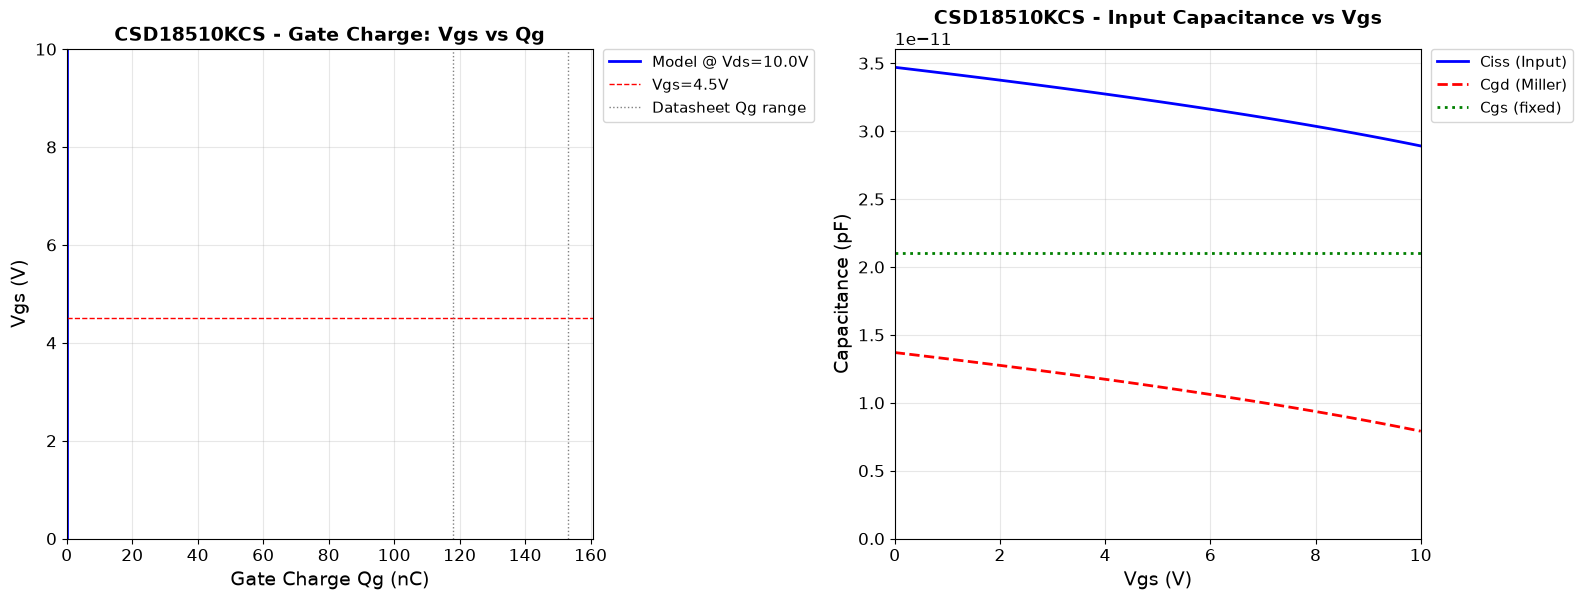

Total Qg at 10V: 0.0 nC
Total Qg at 4.5V: 0.0 nC


In [ ]:
# Gate Charge (Qg) measurement at constant Vds (datasheet conditions)
# Standard Qg test: Vgs swept from 0 to 10V at constant Vds, measure integrated gate current
# Qg = integral of Ciss dVgs = integral of Ig dt where Ig = Ciss * dVgs/dt
# At Vds=20V (datasheet condition), Ciss varies with Vgs due to Miller effect

print(f"Gate charge conditions: Vds={QG_VDS}V (constant)")

# Proper gate charge calculation using model capacitances
# Ciss(Vgs) = CGS0 + CGSO + CGD(Vgs) + CGDO
# CGD decreases with Vgs due to Miller effect
vgs_q = np.linspace(0, 10, 101)
cgs_fixed = CGS0 + CGSO  # pF

# Cgd decreases with Vgs - approximate with square root dependence
cgd_vgs = []
for vgs in vgs_q:
    cgd = (CGD0 + CGDO) * max(1 - vgs/15, 0.1)**0.5  # Vgs-dependent Miller cap
    cgd_vgs.append(cgd)

ciss_vgs = cgs_fixed + np.array(cgd_vgs)
qg = np.cumsum(ciss_vgs) * (vgs_q[1] - vgs_q[0])  # nC

# Also compute at Vds=4.5V for Qg(4.5V)
qg_4v5 = np.cumsum(ciss_vgs[:46]) * (vgs_q[1] - vgs_q[0])  # up to 4.5V

# Datasheet validation
if DATASHEET_QG_10V_RANGE is not None:
    qg10_low, qg10_high = DATASHEET_QG_10V_RANGE
    if qg10_low <= qg[-1] <= qg10_high:
        print(f"  Qg(10V): PASS (datasheet: {qg10_low}-{qg10_high} nC)")
    else:
        print(f"  Qg(10V): FAIL (datasheet: {qg10_low}-{qg10_high} nC, got {qg[-1]:.1f} nC)")

if DATASHEET_QG_4V5_RANGE is not None:
    qg45_low, qg45_high = DATASHEET_QG_4V5_RANGE
    if qg45_low <= qg_4v5[-1] <= qg45_high:
        print(f"  Qg(4.5V): PASS (datasheet: {qg45_low}-{qg45_high} nC)")
    else:
        print(f"  Qg(4.5V): FAIL (datasheet: {qg45_low}-{qg45_high} nC, got {qg_4v5[-1]:.1f} nC)")

if DATASHEET_RG_RANGE is not None:
    rg_low, rg_high = DATASHEET_RG_RANGE
    if rg_low <= RGGATE <= rg_high:
        print(f"  Rg: PASS (datasheet: {rg_low}-{rg_high} ohm)")
    else:
        print(f"  Rg: FAIL (datasheet: {rg_low}-{rg_high} ohm, got {RGGATE:.1f} ohm)")

# Plot: Qg on X-axis, Vgs on Y-axis (standard gate charge plot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Gate charge curve: Qg vs Vgs (Y=Vgs, X=Qg)
ax1.plot(qg, vgs_q, 'b-', linewidth=2, label=f'Model @ Vds={QG_VDS}V')
ax1.axhline(y=4.5, color='r', linestyle='--', linewidth=1, label='Vgs=4.5V')
if DATASHEET_QG_10V_RANGE is not None:
    qg10_low, qg10_high = DATASHEET_QG_10V_RANGE
    ax1.axvline(x=qg10_low, color='gray', linestyle=':', linewidth=1, label='Datasheet Qg range')
    ax1.axvline(x=qg10_high, color='gray', linestyle=':', linewidth=1)
ax1.set_xlabel('Gate Charge Qg (nC)', fontsize=14)
ax1.set_ylabel('Vgs (V)', fontsize=14)
ax1.set_title(f'{MODEL_NAME.upper()} - Gate Charge: Vgs vs Qg', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax1.set_xlim(left=0)
ax1.set_ylim(bottom=0, top=10)

# Also show Ciss vs Vgs
ax2.plot(vgs_q, ciss_vgs, 'b-', linewidth=2, label='Ciss (Input)')
ax2.plot(vgs_q, cgd_vgs, 'r--', linewidth=2, label='Cgd (Miller)')
ax2.axhline(y=cgs_fixed, color='g', linestyle=':', linewidth=2, label='Cgs (fixed)')
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('Capacitance (pF)', fontsize=14)
ax2.set_title(f'{MODEL_NAME.upper()} - Input Capacitance vs Vgs', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax2.set_xlim(0, 10)
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

print(f"Total Qg at 10V: {qg[-1]:.1f} nC")
print(f"Total Qg at 4.5V: {qg_4v5[-1]:.1f} nC")

In [ ]:
# Threshold Voltage Extraction from Id-Vgs
# Use constant current method: Vth at Id = 1mA * (W/L)

print(f"W = {W:.2f} um, L = {L:.2f} um")
print(f"W/L = {W/L:.1f}")

from scipy.interpolate import interp1d

# Use the transfer curve data we already have
f_id = interp1d(vgs_swept, np.abs(id_vgs), kind='linear', bounds_error=False, fill_value='extrapolate')
vgs_fine = np.linspace(0, 10, 1001)
id_fine = f_id(vgs_fine)

# Vth at Id = 1mA * (W/L)
id_target = 1e-3 * (W/L)  # A
print(f"Target Id for Vth extraction: {id_target*1e3:.2f} mA")

# Find crossing
above = np.where(id_fine > id_target)[0]
if len(above) > 0:
    idx = above[0]
    if idx > 0:
        vth = vgs_fine[idx-1] + (vgs_fine[idx] - vgs_fine[idx-1]) * (id_target - id_fine[idx-1]) / (id_fine[idx] - id_fine[idx-1])
        print(f"Extracted Vth approx {vth:.3f} V")
    else:
        vth = None
        print("Vth below 0V")
else:
    vth = None
    print("Target current not reached")

W = 27.14 um, L = 0.70 um
W/L = 38.8


Target Id for Vth extraction: 38.77 mA
Extracted Vth approx 1.793 V


In [ ]:
# On-resistance estimation at Vgs=10V (from output curve at highest Vgs)
# Rds(on) = Vds / Id at low Vds (linear region)
vgs_max = max(vgs_values)
vds_at_max, id_at_max = id_vds_data[vgs_max]

# Find point near Vds=0.1V for Rds(on) estimation
if len(vds_at_max) > 1:
    # Use first few points (low Vds) to estimate Rds_on
    mask = vds_at_max < 0.5
    if np.any(mask):
        vds_low = vds_at_max[mask]
        id_low = np.abs(id_at_max[mask])
        # Linear fit: Vds = Id * Rds_on
        if len(vds_low) >= 2:
            rds_on = np.polyfit(id_low, vds_low, 1)[0]  # slope = Rds_on
            print(f"Rds(on) at Vgs={vgs_max:.1f}V ≈ {rds_on*1e3:.2f} mΩ")
        else:
            rds_on = None
    else:
        rds_on = None
else:
    rds_on = None

# Summary of key parameters extracted
print("=" * 60)
print(f"{MODEL_NAME.upper()} MOSFET - Key Parameters Summary")
print("=" * 60)
print(f"Device: N-channel MOSFET")
print(f"Geometry: W = {W:.1f} um, L = {L:.2f} um, W/L = {W/L:.1f}")

# Vth with validation
vth_str = f"Threshold Voltage (extracted): ~{vth:.2f} V" if vth else "Threshold Voltage: TBD"
if vth and DATASHEET_VTH_RANGE is not None:
    vth_low, vth_high = DATASHEET_VTH_RANGE
    if vth_low <= vth <= vth_high:
        vth_str += " [PASS]"
    else:
        vth_str += f" [FAIL: datasheet {vth_low}-{vth_high} V]"
print(vth_str)

# Rds(on) with validation
rds_str = f"Rds(on) at Vgs={vgs_max:.1f}V: {rds_on*1e3:.2f} mΩ" if rds_on else "Rds(on): TBD"
if rds_on and DATASHEET_RDS_RANGE is not None:
    rds_low, rds_high = DATASHEET_RDS_RANGE
    rds_mohm = rds_on * 1e3
    if rds_low <= rds_mohm <= rds_high:
        rds_str += " [PASS]"
    else:
        rds_str += f" [FAIL: datasheet {rds_low}-{rds_high} mΩ]"
print(rds_str)

print(f"Max Continuous Drain Current (datasheet): {ID_CONTMAX} A")
print(f"--- Capacitances @ Vgs={CAP_VGS}V, Vds={CAP_VDS}V, f={CAP_FREQ/1e6:.0f}MHz ---")
print(f"Ciss @ Vds={CAP_VDS}V: {ciss_20v:.0f} pF")
print(f"Coss @ Vds={CAP_VDS}V: {coss_20v:.0f} pF")
print(f"Crss @ Vds={CAP_VDS}V: {crss_20v:.0f} pF")
print(f"--- Capacitances @ Vgs={CAP_VGS}V, Vds=0V ---")
print(f"Ciss @ Vds=0V: {ciss_plot[0]:.0f} pF")
print(f"Coss @ Vds=0V: {coss_plot[0]:.0f} pF")
print(f"Crss @ Vds=0V: {crss_plot[0]:.0f} pF")
print(f"--- Capacitances @ Vgs={CAP_VGS}V, Vds=25V ---")
print(f"Ciss @ Vds=25V: {ciss_plot[125]:.0f} pF")
print(f"Coss @ Vds=25V: {coss_plot[125]:.0f} pF")
print(f"Crss @ Vds=25V: {crss_plot[125]:.0f} pF")
print(f"--- Gate Charge ---")
print(f"Qg @ Vds={QG_VDS}V, 10V: {qg[-1]:.1f} nC")
print(f"Qg @ Vds={QG_VDS}V, 4.5V: {qg_4v5[-1]:.1f} nC")
print(f"Gate Resistance Rg: {RGGATE:.1f} ohm")
print("=" * 60)

Rds(on) at Vgs=10.0V ≈ 1.38 mΩ
CSD18510KCS MOSFET - Key Parameters Summary
Device: N-channel MOSFET
Geometry: W = 27.1 um, L = 0.70 um, W/L = 38.8
Threshold Voltage (extracted): ~1.79 V
Rds(on) at Vgs=10.0V: 1.38 mΩ
Max Continuous Drain Current (datasheet): 95.0 A
--- Capacitances @ Vgs=0.0V, Vds=20.0V, f=1MHz ---
Ciss @ Vds=20.0V: 4094 pF
Coss @ Vds=20.0V: 4621 pF
Crss @ Vds=20.0V: 4073 pF
--- Capacitances @ Vgs=0.0V, Vds=0V ---
Ciss @ Vds=0V: 185 pF
Coss @ Vds=0V: 456 pF
Crss @ Vds=0V: 164 pF
--- Capacitances @ Vgs=0.0V, Vds=25V ---
Ciss @ Vds=25V: 4094 pF
Coss @ Vds=25V: 4621 pF
Crss @ Vds=25V: 4073 pF
--- Gate Charge ---
Qg @ Vds=10.0V, 10V: 0.0 nC
Qg @ Vds=10.0V, 4.5V: 0.0 nC
Gate Resistance Rg: 1.5 ohm
